# Testing my own trading setup

This notebook produces every number and chart in the write-up ([README.md](README.md)).

Run `python get_intraday.py`, `python get_data.py` and `python backtest.py` first. The rules and the trade simulator are in `setups.py`. This is a backtest of rules on public prices. A computer took every trade, and none of them are a record of anyone's trading.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image

import backtest as b
import charts
import setups as s

pd.options.display.float_format = "{:,.3f}".format
f = b.facts()                                   # every number quoted in the write-up
m15 = pd.read_csv("results/trades_15m.csv")
daily = pd.read_csv("results/trades_daily.csv")
summary = pd.read_csv("results/summary.csv")
print("15 minute settings:", s.MAIN_15M)
print("Daily settings:    ", s.MAIN)
pd.read_csv("results/bar_counts.csv")

15 minute settings: Params(swing=5, window=10, target=2.0, hold=26, cost=2e-05, min_risk=0.002, min_gap=0.25, intraday=True)
Daily settings:     Params(swing=5, window=10, target=2.0, hold=20, cost=0.0002, min_risk=0.002, min_gap=0.25, intraday=False)


,file,bars,days,from,to
0,SPY_15m,12116,466,2025-01-02 09:30,2026-11-13 15:45
1,QQQ_15m,12116,466,2025-01-02 09:30,2026-11-13 15:45
2,SPY_daily,6760,6760,2000-01-03,2026-11-17
3,QQQ_daily,6760,6760,2000-01-03,2026-11-17


The two price sources against each other: the last 15 minute close of each day and the daily close.

In [2]:
pd.read_csv("results/data_check.csv")

,fund,days_compared,days_missing_from_daily,correlation_of_daily_moves,median_gap_pct_last_20_days
0,SPY,466,0,0.998,0.006
1,QQQ,466,0,1.000,0.008


## The setups, as rules

Two real trades from the 15 minute test, one that worked and one that did not.

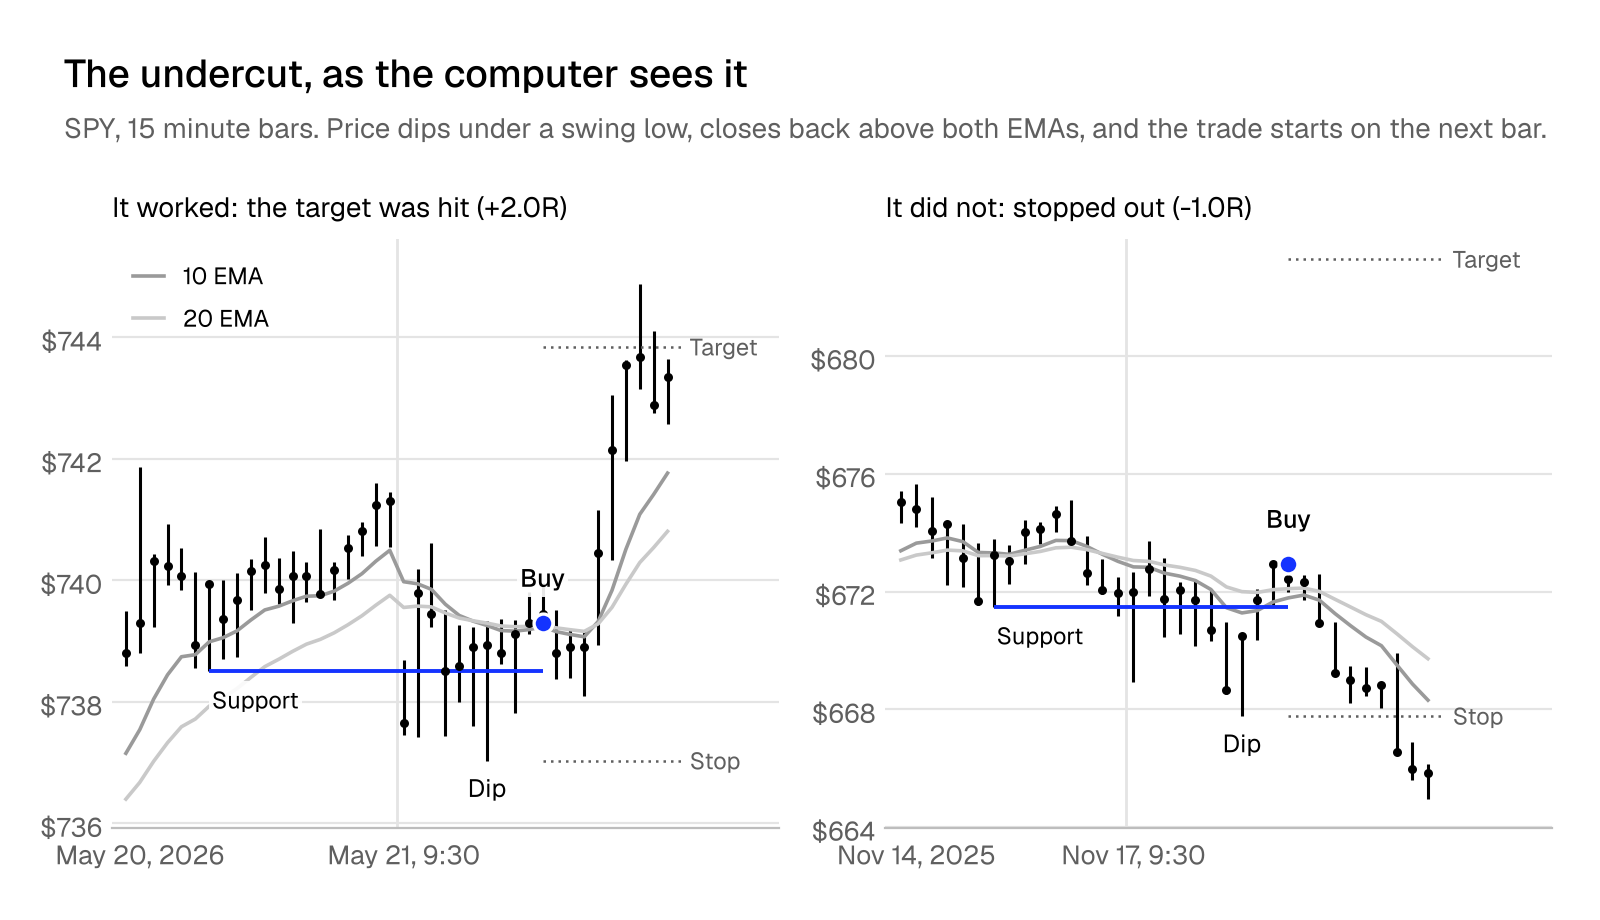

In [3]:
Image(charts.chart_examples(f), width=760)

In [4]:
m15[(m15["symbol"] == "SPY") & (m15["setup"] == "Undercut") & (m15["side"] == "Long")].tail(8)

,symbol,setup,side,signal,entry_time,exit_time,level,entry,stop,risk_pct,bars,r,ended
136,SPY,Undercut,Long,2026-09-28 10:30,2026-09-28 12:30,2026-09-28 15:45,766.290,768.700,763.715,0.648,14,-0.638,time
137,SPY,Undercut,Long,2026-09-29 13:45,2026-09-29 14:30,2026-09-29 15:45,762.570,763.965,762.385,0.207,6,0.148,time
138,SPY,Undercut,Long,2026-10-15 09:30,2026-10-15 10:45,2026-10-15 15:45,766.710,768.980,764.430,0.592,21,0.600,time
139,SPY,Undercut,Long,2026-10-23 15:45,2026-10-26 09:45,2026-10-26 15:45,759.990,762.370,759.550,0.370,25,1.025,time
140,SPY,Undercut,Long,2026-10-29 09:30,2026-10-29 12:00,2026-10-29 13:45,769.620,770.180,767.265,0.378,8,-1.011,stop
141,SPY,Undercut,Long,2026-11-05 15:30,2026-11-06 10:00,2026-11-06 15:45,733.950,740.590,732.710,1.064,24,-0.670,time
142,SPY,Undercut,Long,2026-11-06 15:45,2026-11-09 09:45,2026-11-09 15:45,735.120,746.660,735.070,1.552,25,0.514,time
143,SPY,Undercut,Long,2026-11-11 15:45,2026-11-12 11:00,2026-11-12 15:45,759.700,760.770,753.670,0.933,20,-0.507,time


## The trades on 15 minute bars

Every full trading day from January 2025. Trades are closed by the end of the day they start.

In [5]:
table = summary[summary["timeframe"] == "15m"][["setup", "side", "trades", "win_rate", "avg_r", "avg_r_before_costs", "total_r"]]
u = m15[m15["setup"] == "Undercut"]
print(f"Undercut, both directions: {len(u)} trades, {(u.r > 0).mean():.1%} winners, {u.r.mean():+.3f}R a trade, {u.r.sum():+.1f}R in total")
print("How they ended:", u["ended"].value_counts().to_dict())
print(f"Median stop distance {u.risk_pct.median():.2f}% of price, median length {u.bars.median():.0f} bars")
table.style.format({"win_rate": "{:.1%}", "avg_r": "{:+.3f}", "avg_r_before_costs": "{:+.3f}", "total_r": "{:+.1f}"})

Undercut, both directions: 583 trades, 44.1% winners, -0.071R a trade, -41.2R in total
How they ended: {'time': 372, 'stop': 177, 'target': 34}
Median stop distance 0.55% of price, median length 15 bars


,setup,side,trades,win_rate,avg_r,avg_r_before_costs,total_r
0,Fair value gap,Long,279,42.3%,-0.000,+0.010,-0.0
1,Fair value gap,Short,263,36.9%,-0.048,-0.038,-12.7
2,Undercut,Long,302,47.0%,-0.075,-0.068,-22.7
3,Undercut,Short,281,40.9%,-0.066,-0.057,-18.4


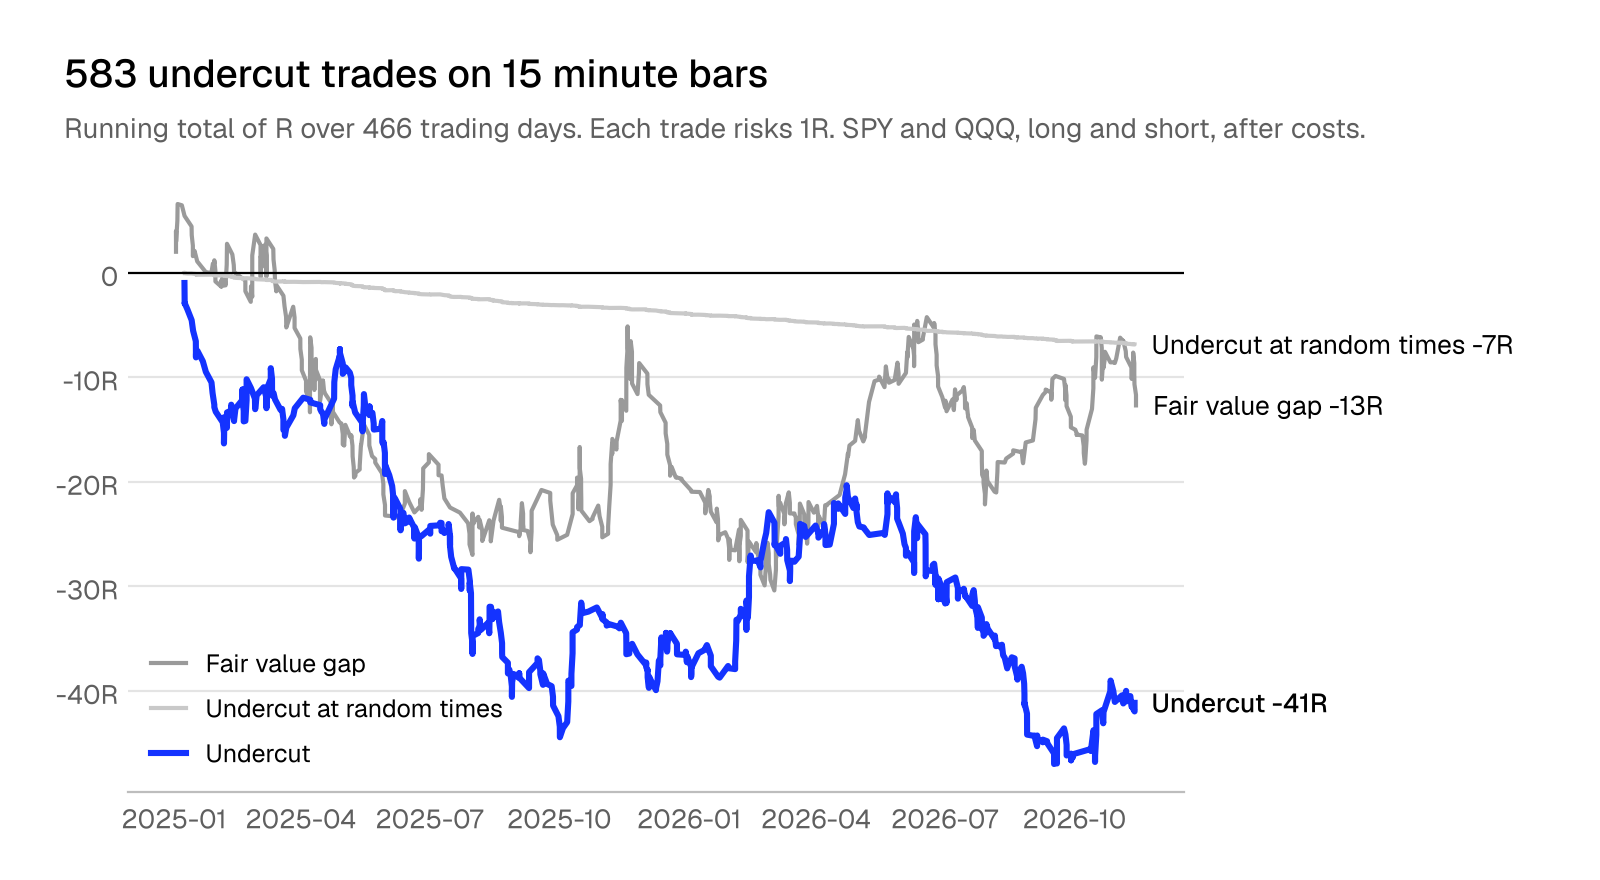

In [6]:
Image(charts.chart_intraday(f), width=760)

## 26 years of daily bars

In [7]:
table = summary[summary["timeframe"] == "daily"][["setup", "side", "trades", "win_rate", "avg_r", "total_r"]]
print(f"Long undercut, 95% range for the average: {f['ul_ci_low']:+.2f}R to {f['ul_ci_high']:+.2f}R")
table.style.format({"win_rate": "{:.1%}", "avg_r": "{:+.3f}", "total_r": "{:+.1f}"})

Long undercut, 95% range for the average: +0.02R to +0.32R


,setup,side,trades,win_rate,avg_r,total_r
4,Fair value gap,Long,857,34.3%,-0.036,-30.8
5,Fair value gap,Short,654,30.7%,-0.079,-51.8
6,Undercut,Long,200,55.5%,+0.168,+33.7
7,Undercut,Short,205,33.7%,-0.159,-32.7


In [8]:
pd.read_csv("results/how_ended.csv").style.format({"avg_r": "{:+.3f}", "total_r": "{:+.1f}"})

,timeframe,side,ended,trades,avg_r,total_r
0,15m,Long,stop,89,-1.009,-89.8
1,15m,Long,target,9,+1.990,+17.9
2,15m,Long,time,204,+0.241,+49.1
3,15m,Short,stop,88,-1.010,-88.9
4,15m,Short,target,25,+1.991,+49.8
5,15m,Short,time,168,+0.123,+20.7
6,daily,Long,stop,75,-1.035,-77.6
7,daily,Long,target,23,+1.996,+45.9
8,daily,Long,time,102,+0.641,+65.3
9,daily,Short,stop,112,-1.041,-116.6


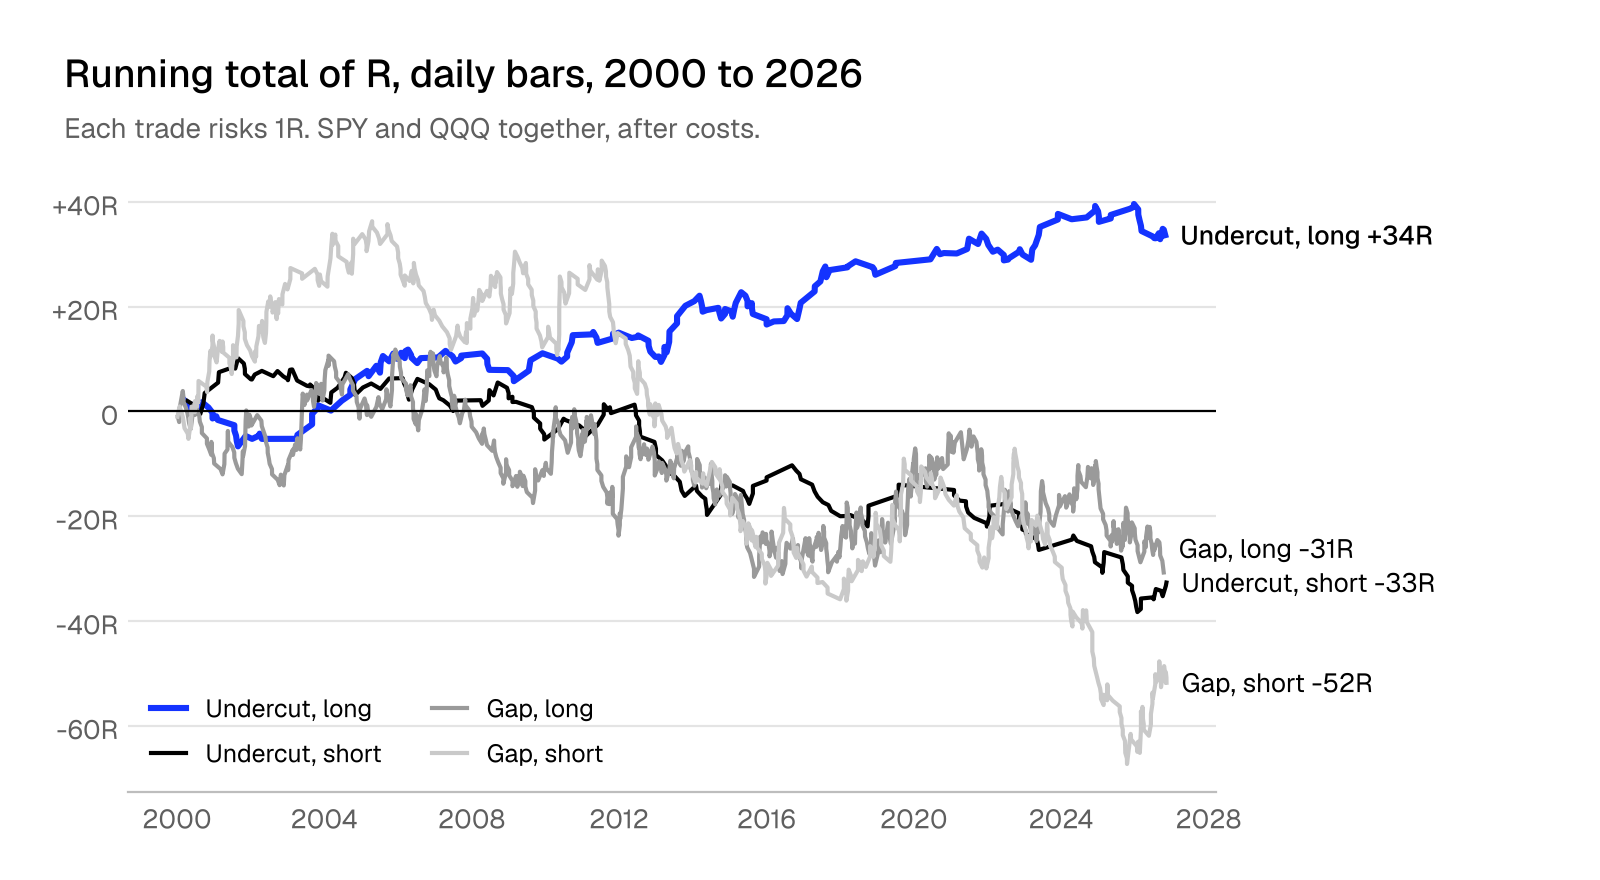

In [9]:
Image(charts.chart_curves(f), width=760)

## Was it the setup, or the market?

For every real trade, 200 copies at random times with the same direction, stop distance, target and time limit. `chance_random_does_as_well` is the share of random sets of the same size whose average was at least as good as the real one.

In [10]:
pd.read_csv("results/buy_and_hold.csv").style.format({"total_return": "{:.0%}", "per_year": "{:.1%}", "worst_drop": "{:.0%}"})

,symbol,from,to,total_return,per_year,worst_drop
0,SPY,2000-01-03,2026-11-17,706%,8.1%,-55%
1,QQQ,2000-01-03,2026-11-17,724%,8.2%,-83%


In [11]:
summary[["timeframe", "setup", "side", "avg_r", "random_avg_r", "edge_r", "chance_random_does_as_well"]].style.format({"avg_r": "{:+.3f}", "random_avg_r": "{:+.3f}", "edge_r": "{:+.3f}", "chance_random_does_as_well": "{:.1%}"})

,timeframe,setup,side,avg_r,random_avg_r,edge_r,chance_random_does_as_well
0,15m,Fair value gap,Long,-0.000,-0.032,+0.032,28.5%
1,15m,Fair value gap,Short,-0.048,-0.001,-0.047,78.0%
2,15m,Undercut,Long,-0.075,-0.026,-0.049,86.5%
3,15m,Undercut,Short,-0.066,+0.003,-0.069,91.3%
4,daily,Fair value gap,Long,-0.036,-0.080,+0.044,19.0%
5,daily,Fair value gap,Short,-0.079,-0.211,+0.132,0.8%
6,daily,Undercut,Long,+0.168,+0.120,+0.048,27.1%
7,daily,Undercut,Short,-0.159,-0.143,-0.016,57.9%


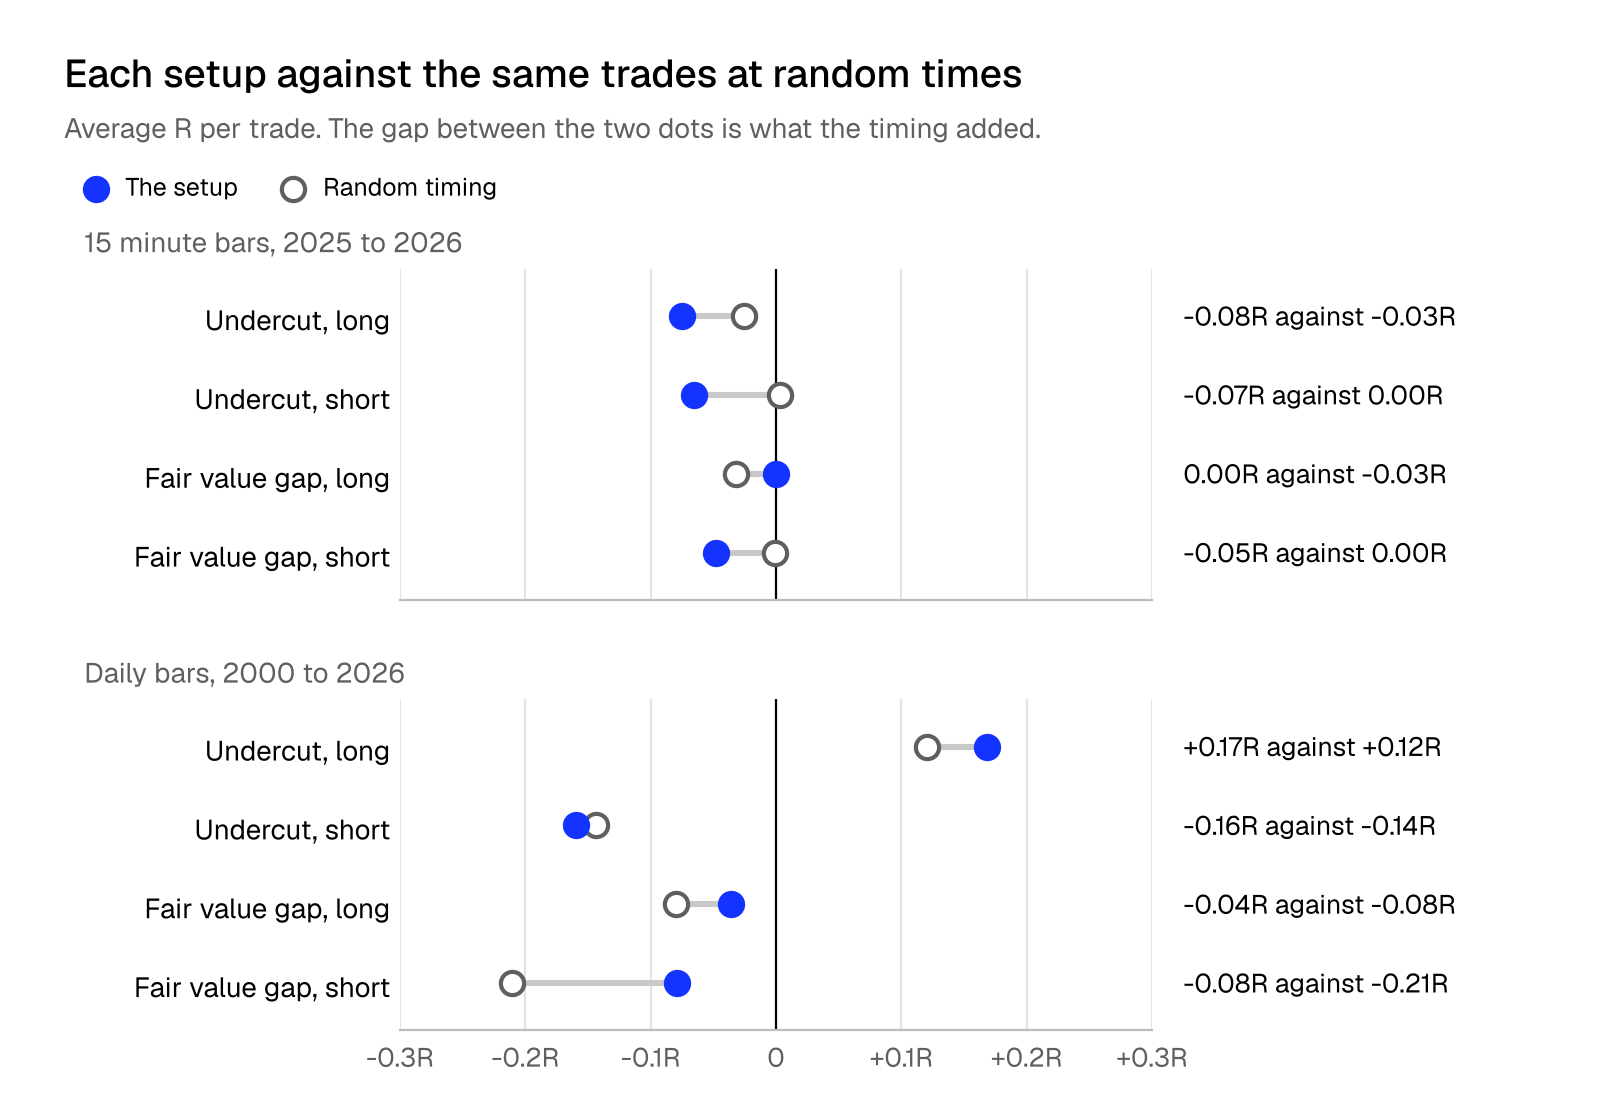

In [12]:
Image(charts.chart_vs_random(f), width=760)

## Does the daily long side hold up?

In [13]:
period = pd.read_csv("results/by_period.csv")
period[period["setup"] == "Undercut"].pivot(index="period", columns="side", values="avg_r").style.format("{:+.3f}")

side,Long,Short
period,,
2000 to 2009,+0.163,-0.065
2010 to 2019,+0.216,-0.127
2020 to 2026,+0.102,-0.346


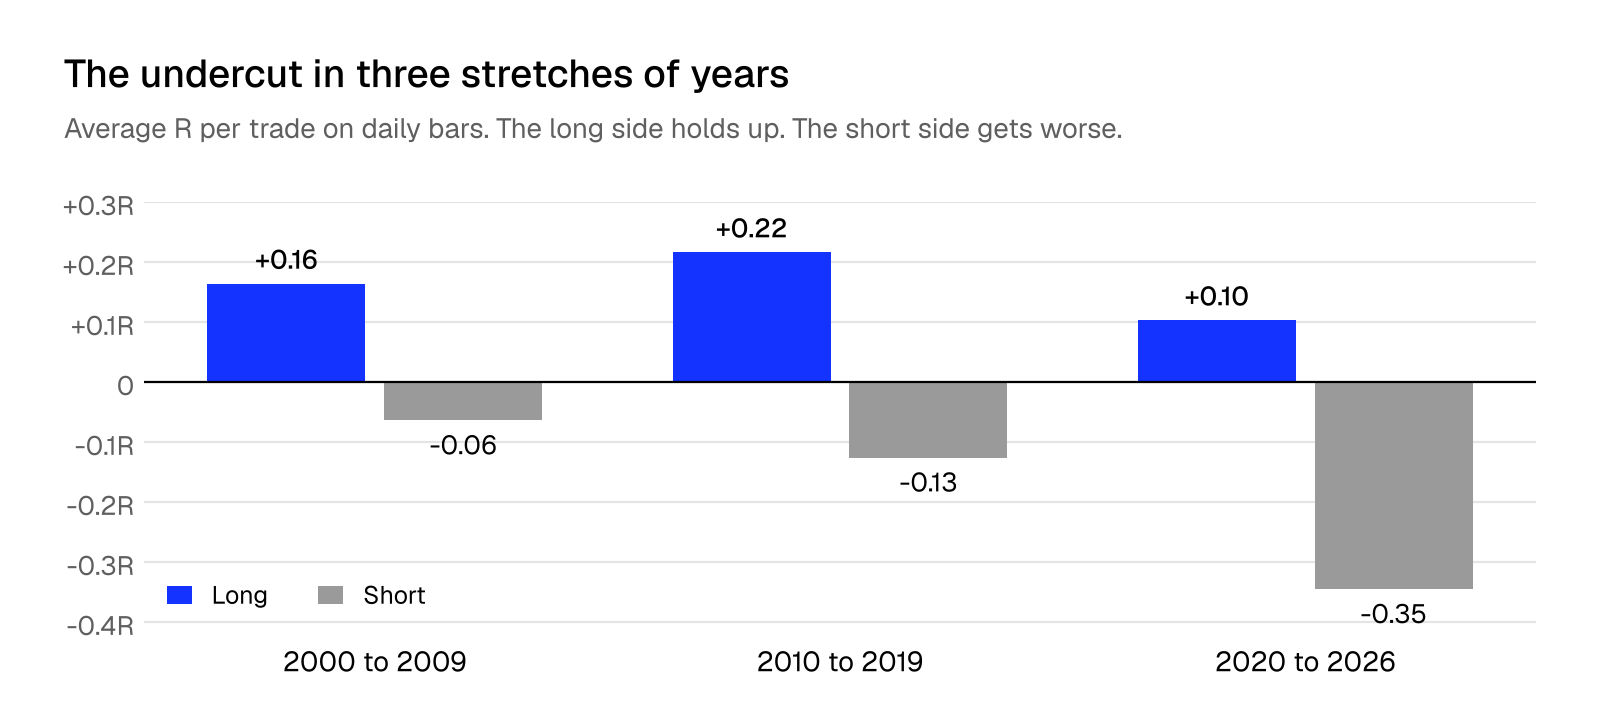

In [14]:
Image(charts.chart_periods(f), width=760)

       settings  profitable  beat_random  lowest  highest
side                                                     
Long         27          27           18   0.024    0.219
Short        27           3           20  -0.247    0.055


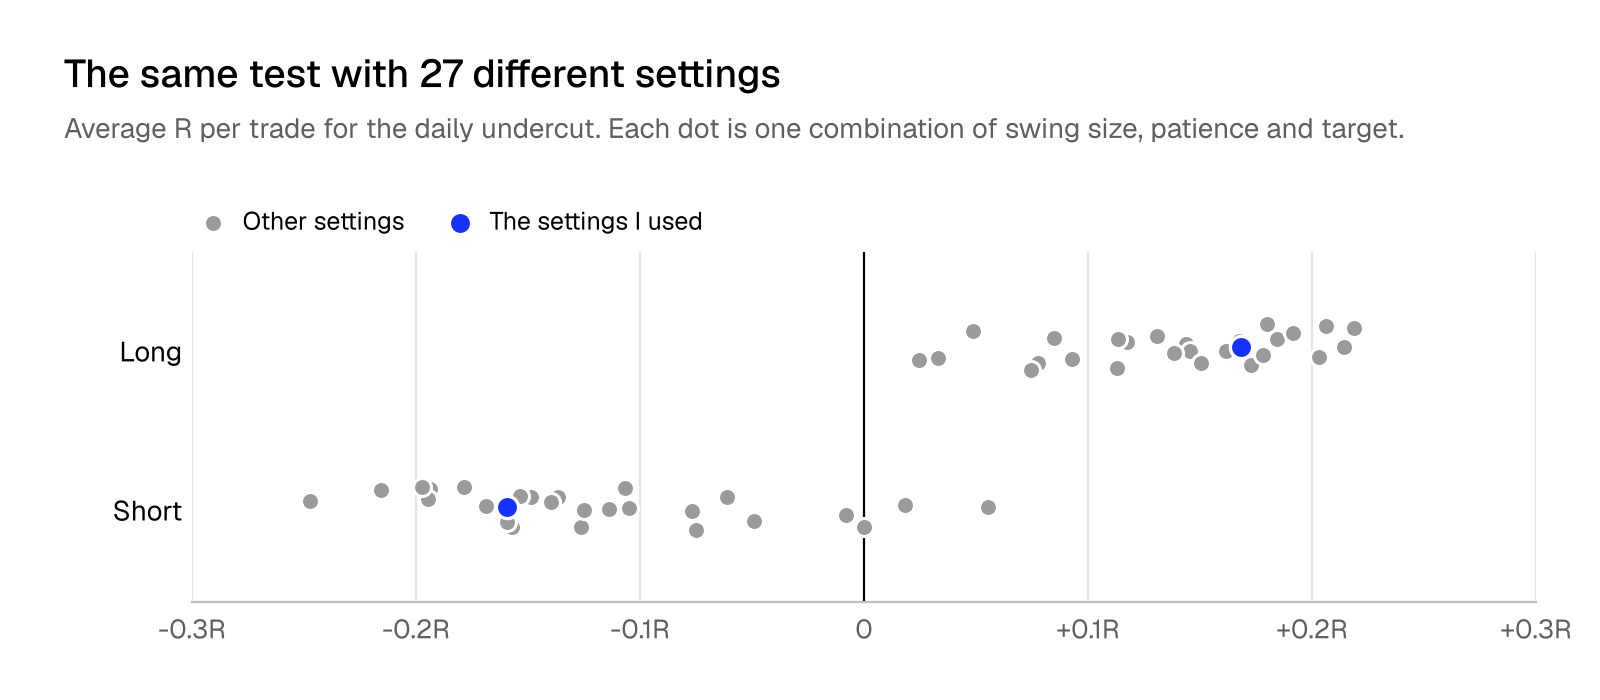

In [15]:
sens = pd.read_csv("results/sensitivity.csv")
print(sens.groupby("side").agg(settings=("avg_r", "size"), profitable=("avg_r", lambda x: int((x > 0).sum())), beat_random=("edge_r", lambda x: int((x > 0).sum())), lowest=("avg_r", "min"), highest=("avg_r", "max")))
Image(charts.chart_settings(f), width=760)

## What waiting was worth

The undercut as written waits for the reclaim. The impatient version buys the open of the bar after the dip. Trades with a stop closer than `min_stop` of the price are skipped, so the comparison is shown at the main filter (0.002) and a looser one (0.001).

In [16]:
pd.read_csv("results/waiting.csv").style.format({"win_rate": "{:.1%}", "avg_r": "{:+.3f}", "total_r": "{:+.1f}"})

,timeframe,min_stop,side,version,trades,win_rate,avg_r,total_r
0,15m,0.002000,Long,Waits for the reclaim,302,47.0%,-0.075,-22.7
1,15m,0.002000,Long,Buys the dip,137,36.5%,-0.092,-12.6
2,15m,0.002000,Short,Waits for the reclaim,281,40.9%,-0.066,-18.4
3,15m,0.002000,Short,Buys the dip,107,35.5%,-0.095,-10.1
4,15m,0.001000,Long,Waits for the reclaim,314,46.8%,-0.075,-23.5
5,15m,0.001000,Long,Buys the dip,263,37.3%,-0.002,-0.6
6,15m,0.001000,Short,Waits for the reclaim,296,40.2%,-0.083,-24.4
7,15m,0.001000,Short,Buys the dip,215,34.4%,-0.080,-17.2
8,daily,0.002000,Long,Waits for the reclaim,200,55.5%,+0.168,+33.7
9,daily,0.002000,Long,Buys the dip,243,28.8%,-0.226,-55.0


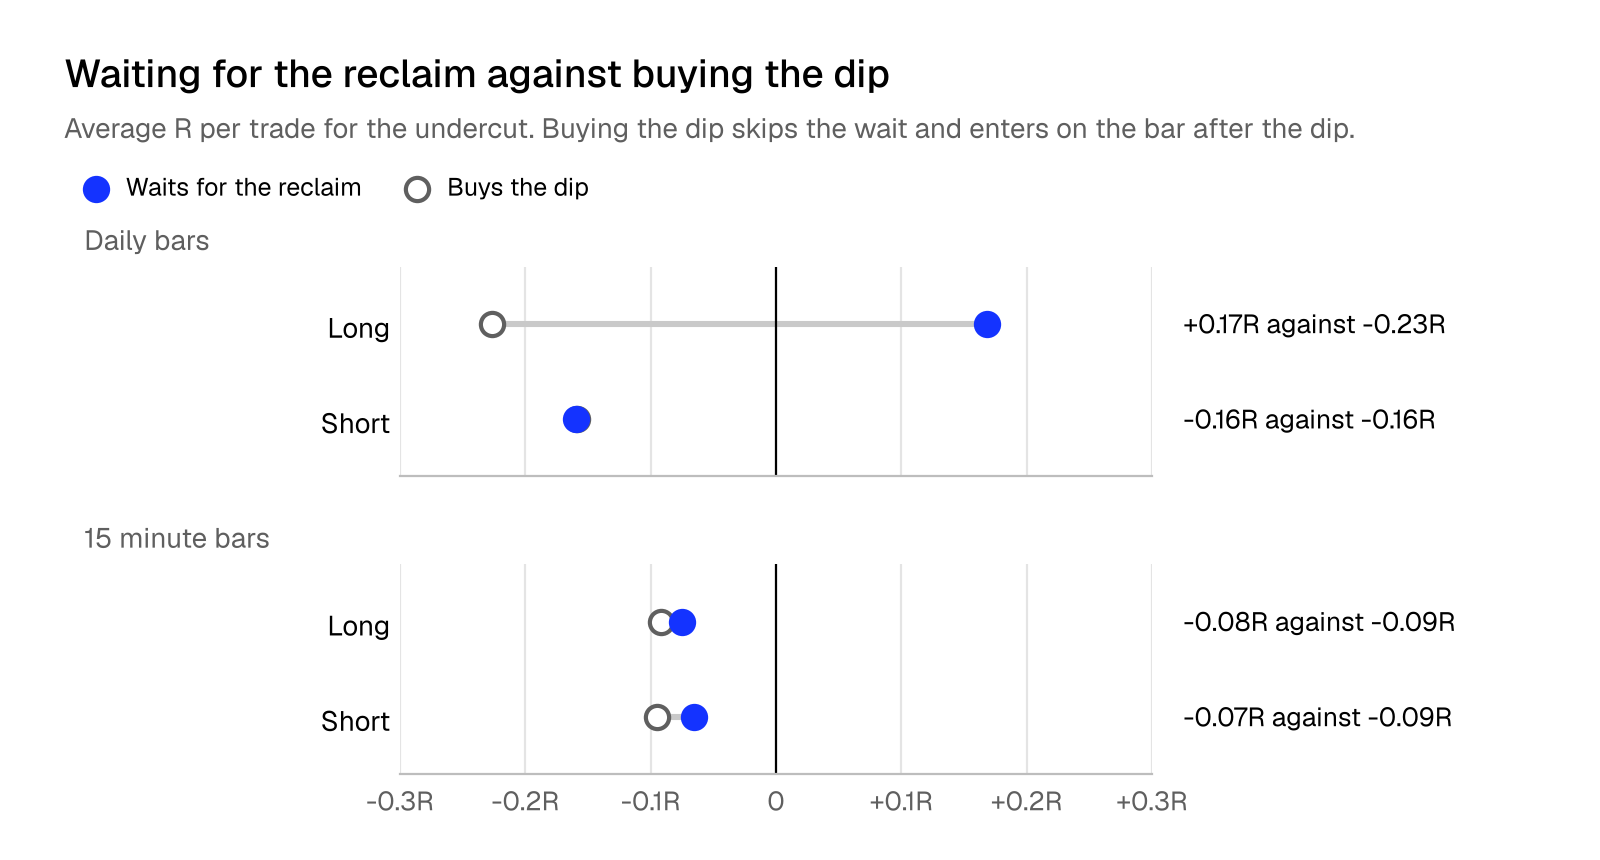

In [17]:
Image(charts.chart_waiting(f), width=760)

Days with no undercut trade at all, and the 15 minute trades by the hour they started.

In [18]:
pd.read_csv("results/quiet_days.csv")

,fund,days,days_with_a_trade,days_without
0,SPY,466,207,259
1,QQQ,466,227,239
2,Either,466,284,182


In [19]:
pd.read_csv("results/by_hour.csv").style.format({"avg_r": "{:+.3f}", "total_r": "{:+.1f}"})

,hour,trades,avg_r,total_r
0,9,149,+0.009,+1.3
1,10,148,-0.137,-20.3
2,11,86,+0.025,+2.2
3,12,61,-0.062,-3.8
4,13,45,-0.162,-7.3
5,14,57,-0.195,-11.1
6,15,37,-0.056,-2.1


## What it means in money

In [20]:
print(f"15 minute undercut: {f['m15_u_total']:+.1f}R in total over {f['m15_days']} days. At half a percent a trade that is {f['m15_u_total'] / 2:+.0f}% of the account.")
print(f"Daily long undercut: {f['daily_ul_total']:+.1f}R in total, worst losing run {f['ul_worst_run']:.1f}R, in a trade {f['ul_time_in_trade']:.0%} of the time.")
print(f"Holding SPY: {f['hold_total_SPY']:.0%} in total, worst drop {f['hold_drop_SPY']:.0%}.")
print(f"Holding QQQ: {f['hold_total_QQQ']:.0%} in total, worst drop {f['hold_drop_QQQ']:.0%}.")

15 minute undercut: -41.2R in total over 466 days. At half a percent a trade that is -21% of the account.
Daily long undercut: +33.7R in total, worst losing run -8.7R, in a trade 21% of the time.
Holding SPY: 706% in total, worst drop -55%.
Holding QQQ: 724% in total, worst drop -83%.
